# Figure 2: Full QC-passed cohort method comparison

This notebook displays Figure 2A/B beyond the historical 50-subject comparison. Existing results are preserved. The same 21 pial-to-white depths, anatomical mask, pairwise validity, profile correlation, MAE, symmetric normalized MAE and shared barycentric curvature definitions are retained.

**Two analysis sets:** (1) the maximum available subjects for each method pair, and (2) the common subjects with both comparisons available. Primary between-method interpretation uses the common cohort, so different sample composition cannot masquerade as a method effect. Missing O2-Column native inputs are method-specific unavailability, not new registration QC failures. The five established registration QC exclusions remain excluded; there is no Figure 5 CN restriction.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'analysis_results/figure2/full_cohort.py').is_file())
submission = json.loads((REPO / 'analysis_results/figure2/full_cohort_submission.json').read_text())
OUTPUT = Path(submission['output_dir'])
if not (OUTPUT / 'results_complete.json').is_file():
    raise RuntimeError('Full-cohort tasks or final plotting are still running; see full_cohort_submission.json and SLURM logs.')
report = json.loads((OUTPUT / 'analysis_complete.json').read_text())
subjects = pd.read_csv(OUTPUT / 'subjects.csv')
inventory = pd.read_csv(OUTPUT / 'candidate_inventory.csv')
display(pd.DataFrame({'analysis': ['QC-passed Option 3 cohort', 'Common comparison subjects'],
                      'N': [report['n_qc_passed_subjects'], report['n_common_subjects']]}))
display(pd.Series(report['comparison_subject_counts'], name='Maximum available N').to_frame())
excluded = pd.read_csv(REPO / 'manifests/figure4_registration_qc_exclusions.csv')
assert set(excluded.subject_id).isdisjoint(subjects.subject_id)
display(excluded)
display(subjects.loc[~subjects.o2_column_input_available, ['subject_id', 'o2_column_unavailable_reason']])


,analysis,N
0,QC-passed Option 3 cohort,320
1,Common comparison subjects,293


,Maximum available N
O2Column_vs_O3,293
O2FS_vs_O3,320


,subject_id,qc_status,qc_reason
0,D0128,fail,visual T1-DWI registration failure
1,D0163,fail,visual T1-DWI registration failure
2,D0248,fail,visual T1-DWI registration failure
3,D0296,fail,visual T1-DWI registration failure
4,D0388,fail,severe T1-DWI misalignment; catastrophic 12-DO...


,subject_id,o2_column_unavailable_reason
47,D0102,Missing comparable archived native-column inputs
114,D0178,Missing comparable archived native-column inputs
116,D0180,Missing comparable archived native-column inputs
117,D0183,Missing comparable archived native-column inputs
120,D0186,Missing comparable archived native-column inputs
121,D0187,Missing comparable archived native-column inputs
122,D0189,Missing comparable archived native-column inputs
123,D0190,Missing comparable archived native-column inputs
124,D0191,Missing comparable archived native-column inputs
125,D0192,Missing comparable archived native-column inputs


## Matched common cohort

Each distribution point is a subject-level median over valid cortical vertices pooled within that subject across hemispheres. Group summaries weight subjects equally. Surface maps use the Fisher mean of per-subject profile correlations at each vertex; vertices require at least 80% subject coverage. Surface maps use blue–white–red colors (RdBu_r), with r=0.98–1.00 for O2-Column versus O3 and r=0.8–1.00 for O2-FS versus O3. Each comparison shares limits across hemispheres/views; compare numeric summaries rather than colors across methods.


,comparison,metric,n_subjects,median,q25,q75,ci95_lower,ci95_upper,subject_wilcoxon_statistic,subject_wilcoxon_pvalue
0,O2Column_vs_O3,profile_r,293,0.996847,0.996253,0.997348,0.996668,0.996951,NaN,NaN
1,O2Column_vs_O3,profile_mae,293,0.000013,0.000012,0.000014,0.000013,0.000013,NaN,NaN
2,O2Column_vs_O3,profile_snmae_pct,293,1.726371,1.602338,1.881400,1.702088,1.765359,NaN,NaN
3,O2Column_vs_O3,curvature_mae_spearman,293,0.003521,-0.005146,0.015757,0.001601,0.005677,14328.0,6.852123e-07
4,O2FS_vs_O3,profile_r,293,0.872003,0.845136,0.905036,0.867131,0.880440,NaN,NaN
5,O2FS_vs_O3,profile_mae,293,0.000122,0.000108,0.000137,0.000119,0.000125,NaN,NaN
6,O2FS_vs_O3,profile_snmae_pct,293,16.496027,14.873937,18.424539,16.158517,17.047858,NaN,NaN
7,O2FS_vs_O3,curvature_mae_spearman,293,0.042108,0.022806,0.058883,0.039059,0.046132,684.0,8.536675e-47


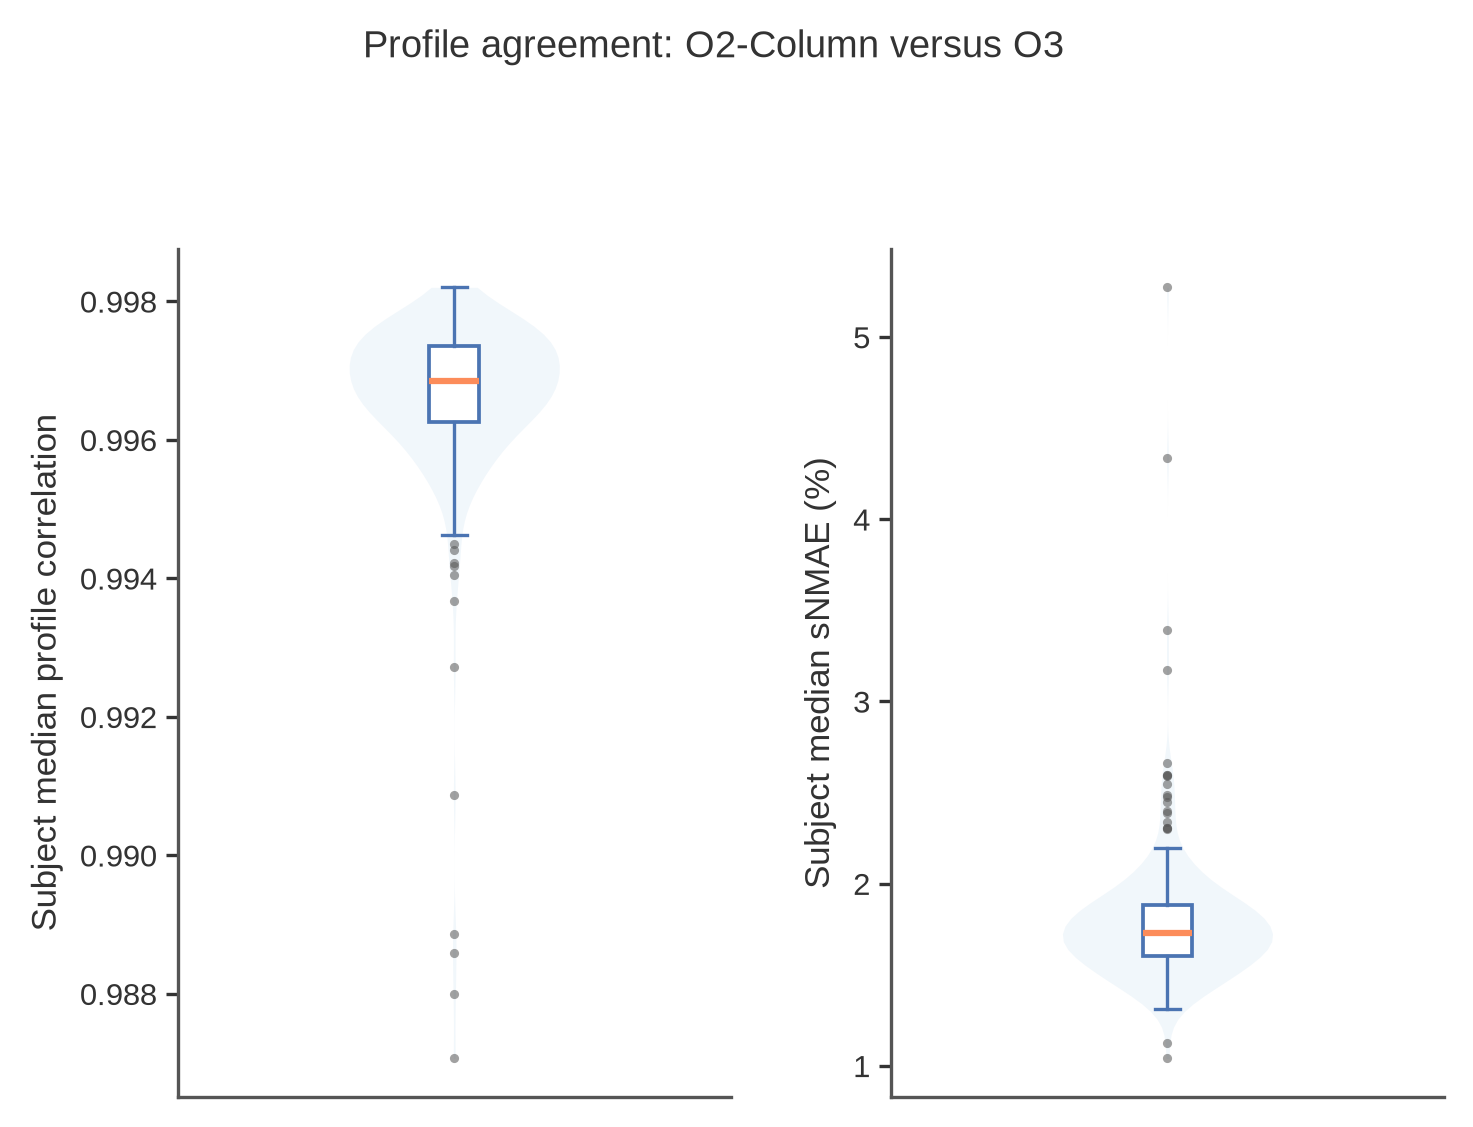

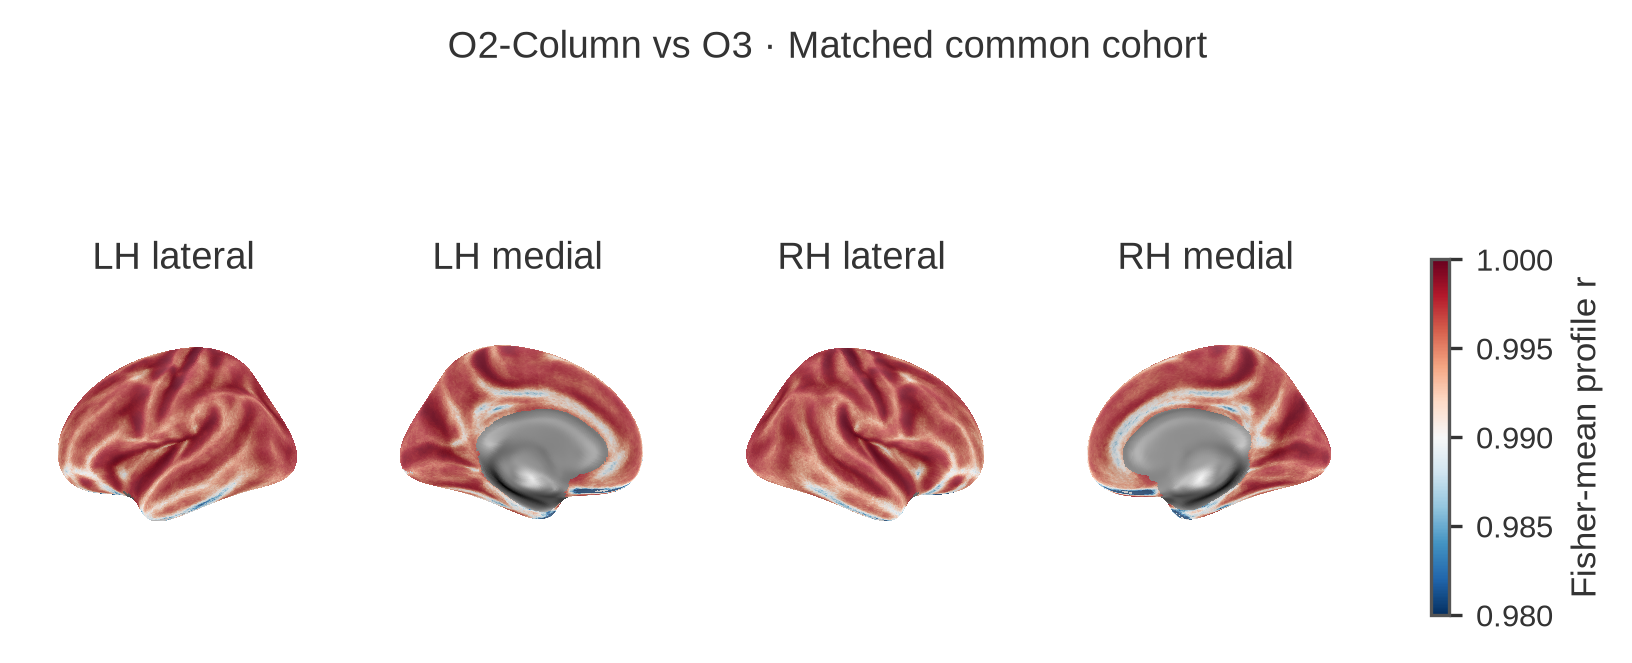

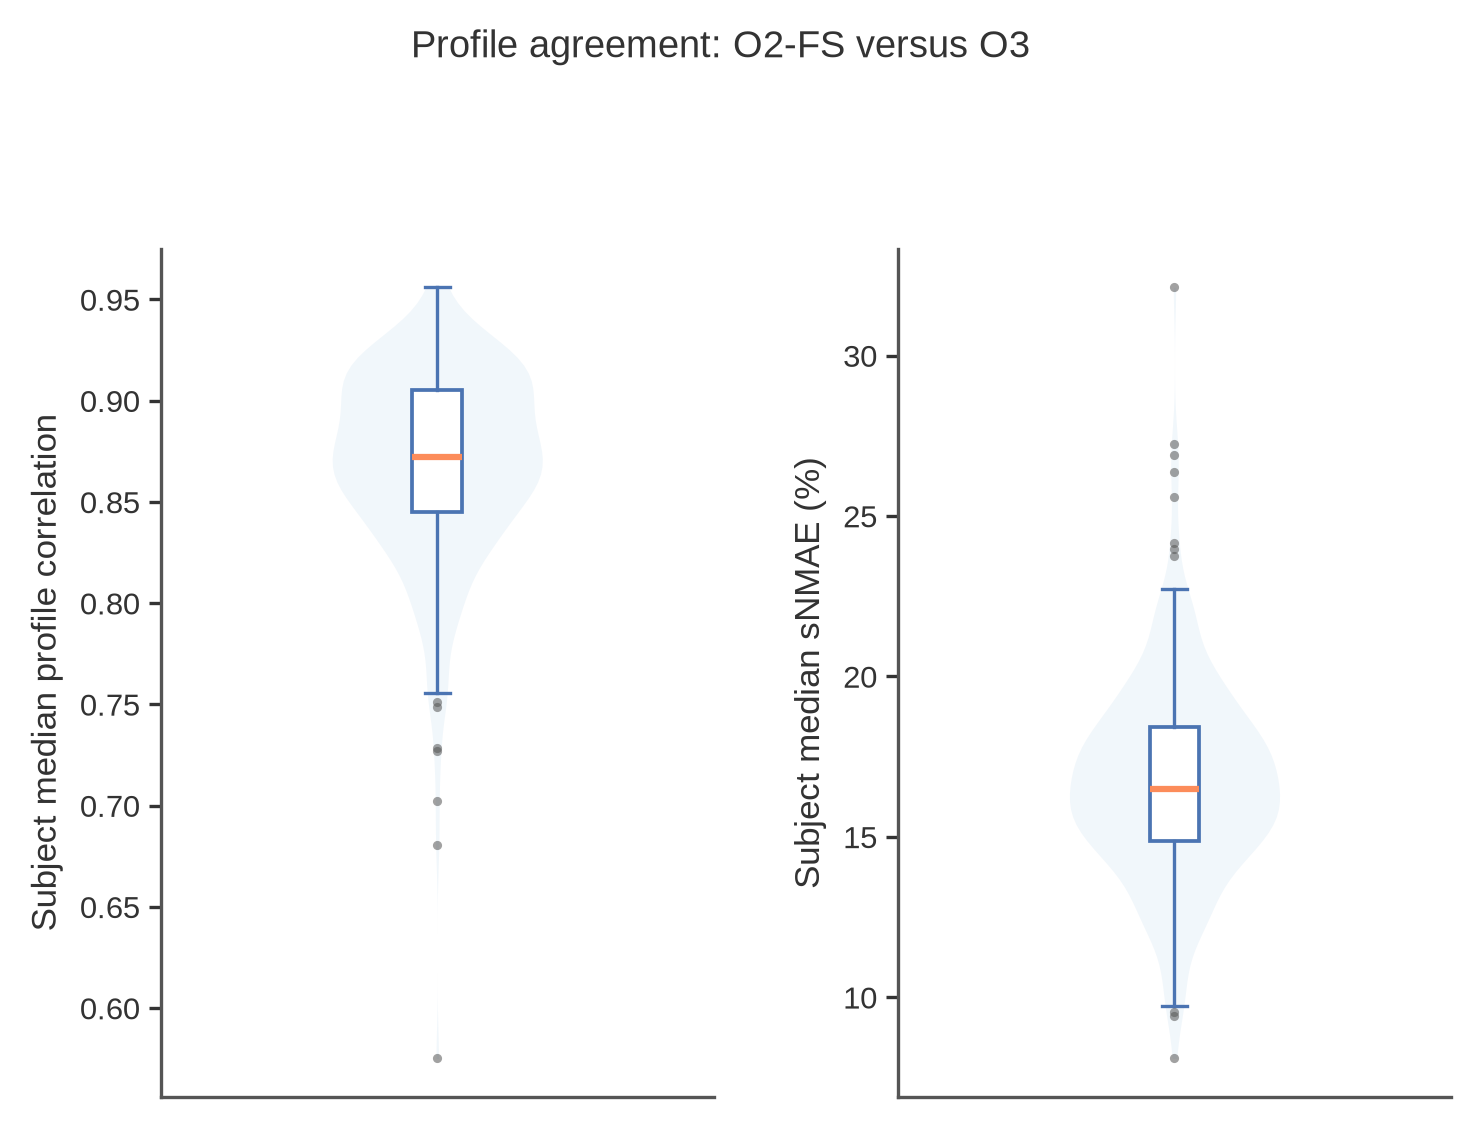

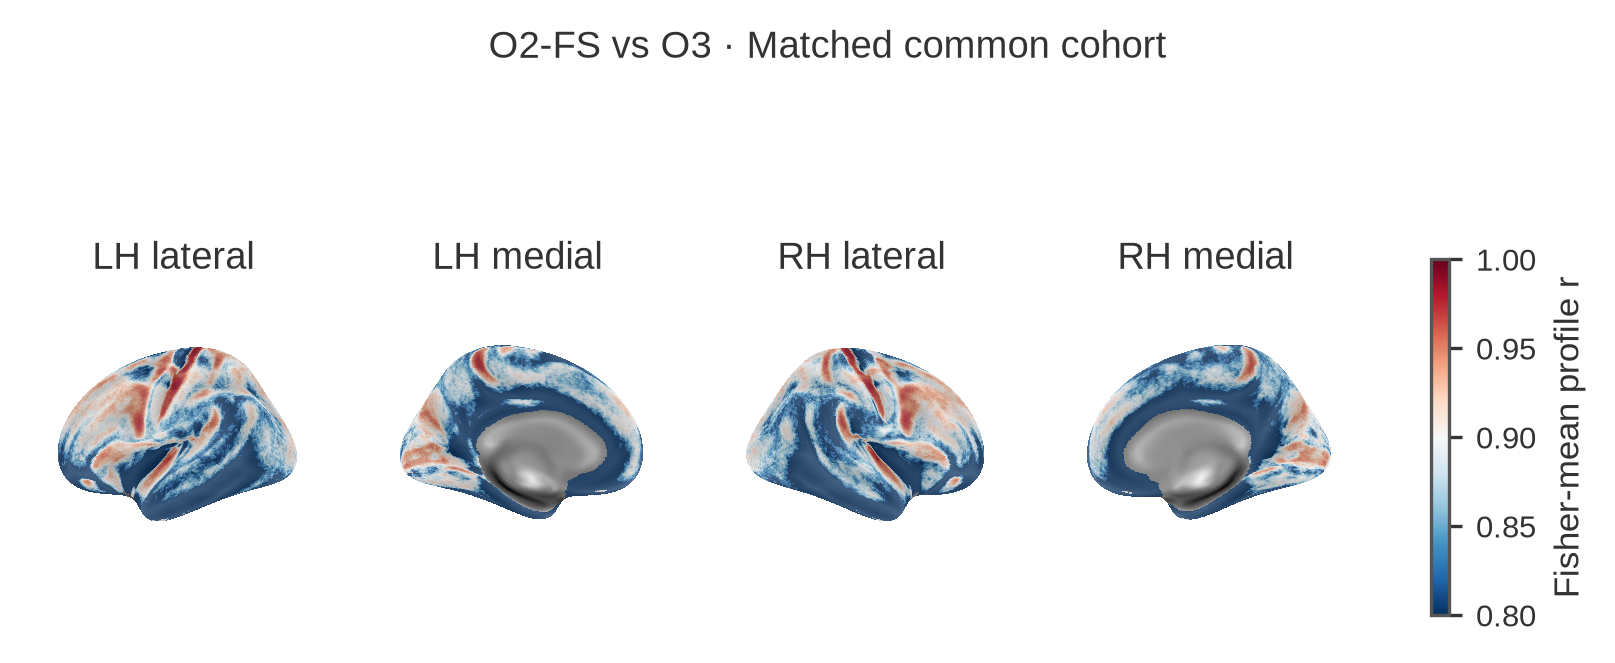

Blue–white–red surface agreement maps (RdBu_r): O2-Column versus O3 uses r=0.98–1.00; O2-FS versus O3 uses r=0.8–1.00. Blue is lower and red is higher within the stated display range. All hemispheres and views of a given comparison use identical limits. Ranges differ between comparisons, so use numeric r values and subject summaries for between-method comparisons. Values outside the display limits are color-saturated; source correlations and masks are unchanged. Missing vertices are gray.


In [2]:
common = pd.read_csv(OUTPUT / 'common_cohort/subject_summary.csv')
display(common)
display_widths = {
    'Figure2_common_cohort_O2Column_vs_O3_agreement': 760,
    'Figure2A_common_cohort_O2Column_vs_O3_surface': 1300,
    'Figure2_common_cohort_O2FS_vs_O3_agreement': 760,
    'Figure2A_common_cohort_O2FS_vs_O3_surface': 1300,
}
for stem, width in display_widths.items():
    display(Image(filename=str(OUTPUT / 'figures' / f'{stem}.png'), width=width))
display(Markdown((OUTPUT / 'figures/Figure2_surface_maps_caption.txt').read_text()))


## Curvature dependence

Within each subject, both hemispheres are pooled before assigning 10 equal-frequency curvature bins. Each subject contributes at most one median MAE per bin. Shading is the between-subject IQR. Spatial Spearman correlations are computed separately per subject. Bootstrap intervals and Wilcoxon tests use subjects as independent units, not vertices. The shared curvature is the barycentrically mapped absolute native curvature used in the original analysis.


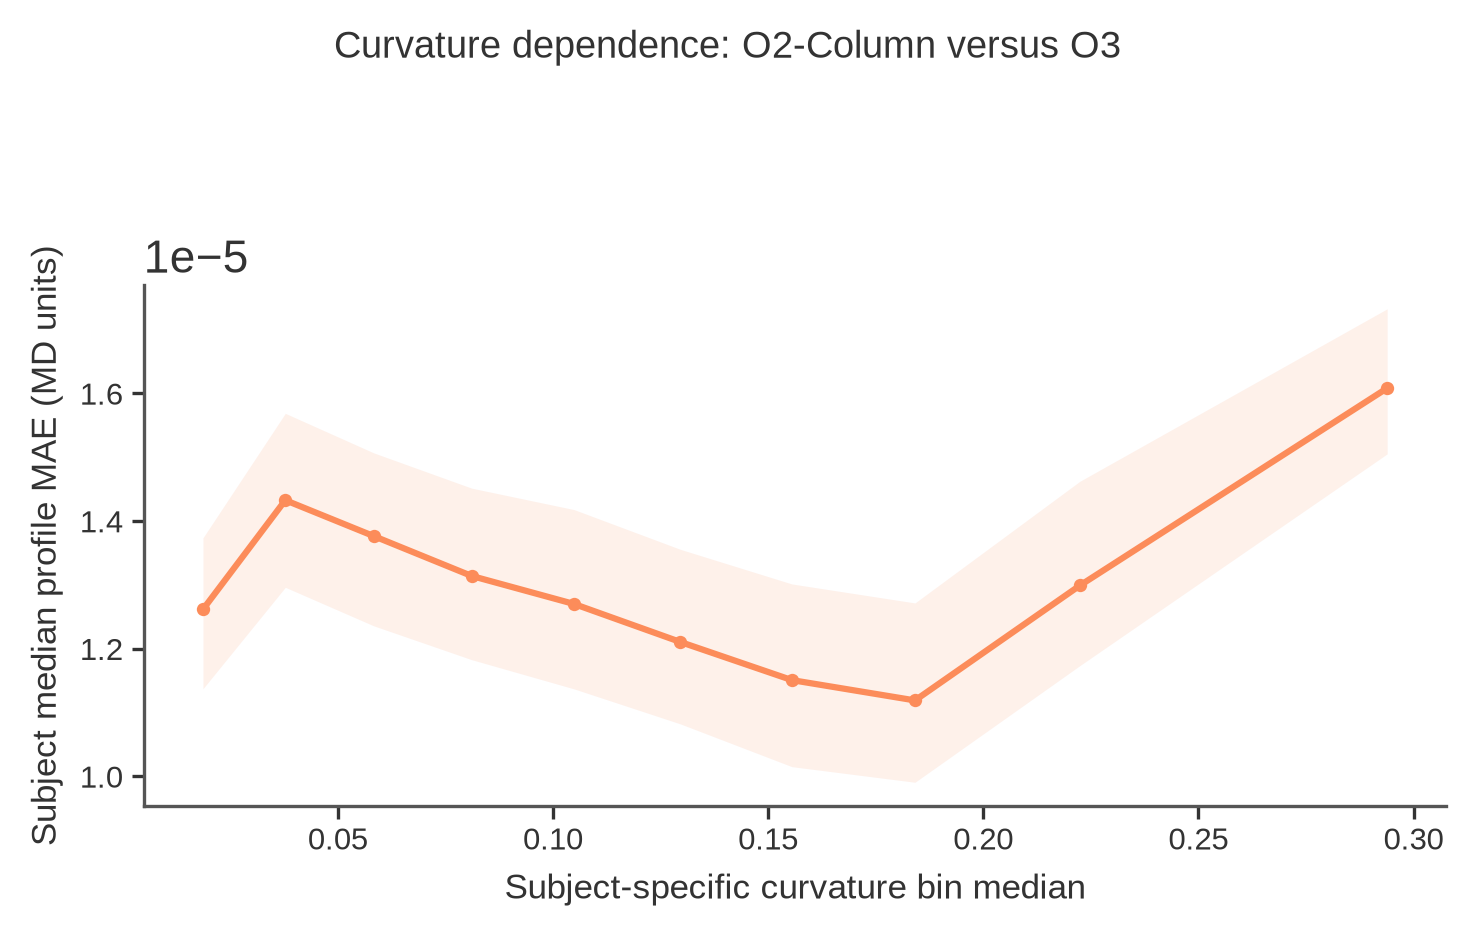

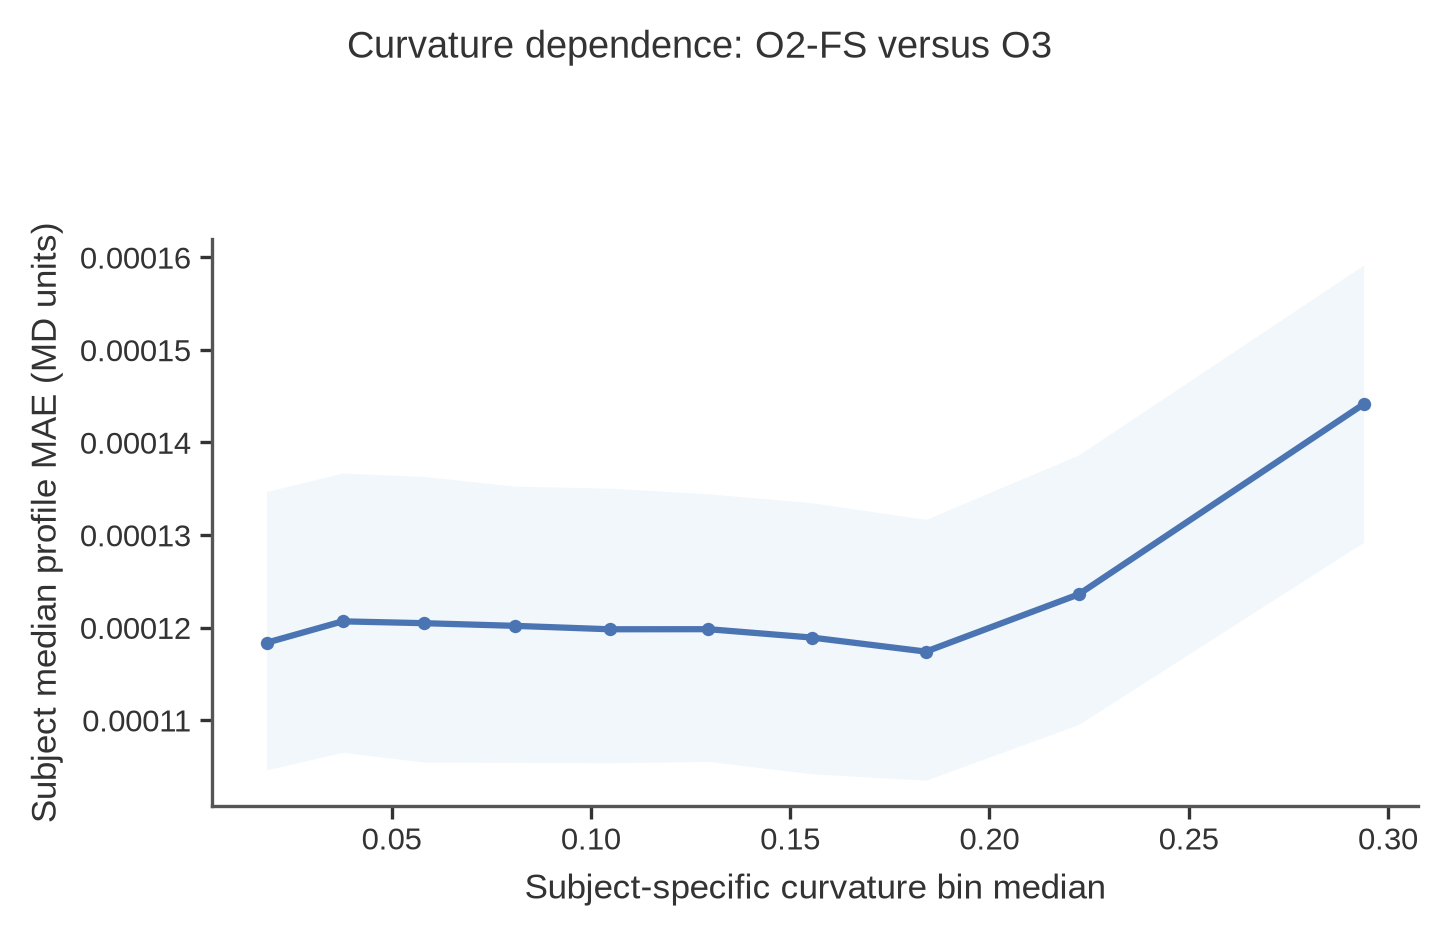

,comparison,metric,n_subjects,median,q25,q75,ci95_lower,ci95_upper,subject_wilcoxon_statistic,subject_wilcoxon_pvalue
3,O2Column_vs_O3,curvature_mae_spearman,293,0.003521,-0.005146,0.015757,0.001601,0.005677,14328.0,6.852123e-07
7,O2FS_vs_O3,curvature_mae_spearman,293,0.042108,0.022806,0.058883,0.039059,0.046132,684.0,8.536675e-47


In [3]:
for slug in ['O2Column_vs_O3', 'O2FS_vs_O3']:
    display(Image(filename=str(OUTPUT / 'figures' / f'Figure2_common_cohort_{slug}_curvature.png'), width=1200))
display(common.loc[common.metric.eq('curvature_mae_spearman')])


## Maximum available samples

These results include all available QC-passed subjects for each pair. Ns may differ because the comparable archived native inputs required by O2-Column are unavailable for some subjects. Do not interpret differences between these distributions as paired comparisons when subject sets differ.


,comparison,metric,n_subjects,median,q25,q75,ci95_lower,ci95_upper,subject_wilcoxon_statistic,subject_wilcoxon_pvalue
0,O2Column_vs_O3,profile_r,293,0.996847,0.996253,0.997348,0.996668,0.996951,NaN,NaN
1,O2Column_vs_O3,profile_mae,293,0.000013,0.000012,0.000014,0.000013,0.000013,NaN,NaN
2,O2Column_vs_O3,profile_snmae_pct,293,1.726371,1.602338,1.881400,1.702088,1.765359,NaN,NaN
3,O2Column_vs_O3,curvature_mae_spearman,293,0.003521,-0.005146,0.015757,0.001601,0.005677,14328.0,6.852123e-07
4,O2FS_vs_O3,profile_r,320,0.873849,0.842112,0.906006,0.868688,0.881244,NaN,NaN
5,O2FS_vs_O3,profile_mae,320,0.000123,0.000107,0.000136,0.000119,0.000125,NaN,NaN
6,O2FS_vs_O3,profile_snmae_pct,320,16.547912,14.732327,18.377086,16.159003,17.068593,NaN,NaN
7,O2FS_vs_O3,curvature_mae_spearman,320,0.042443,0.023750,0.059798,0.039416,0.046449,728.0,2.772930e-51


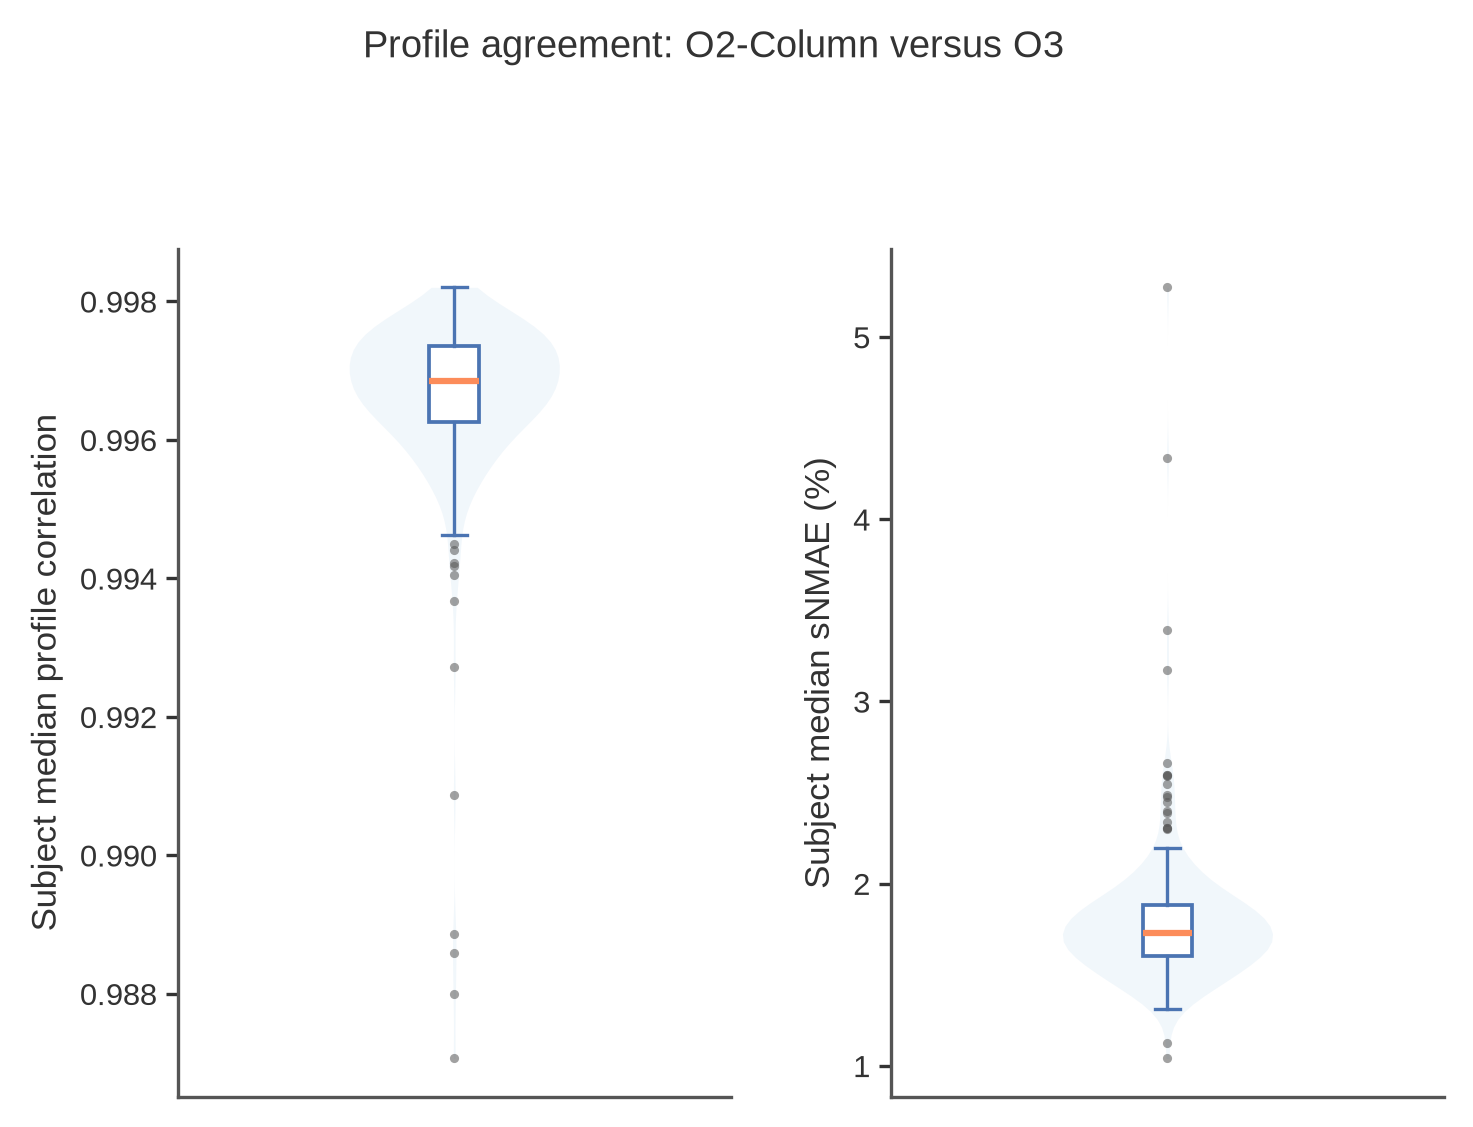

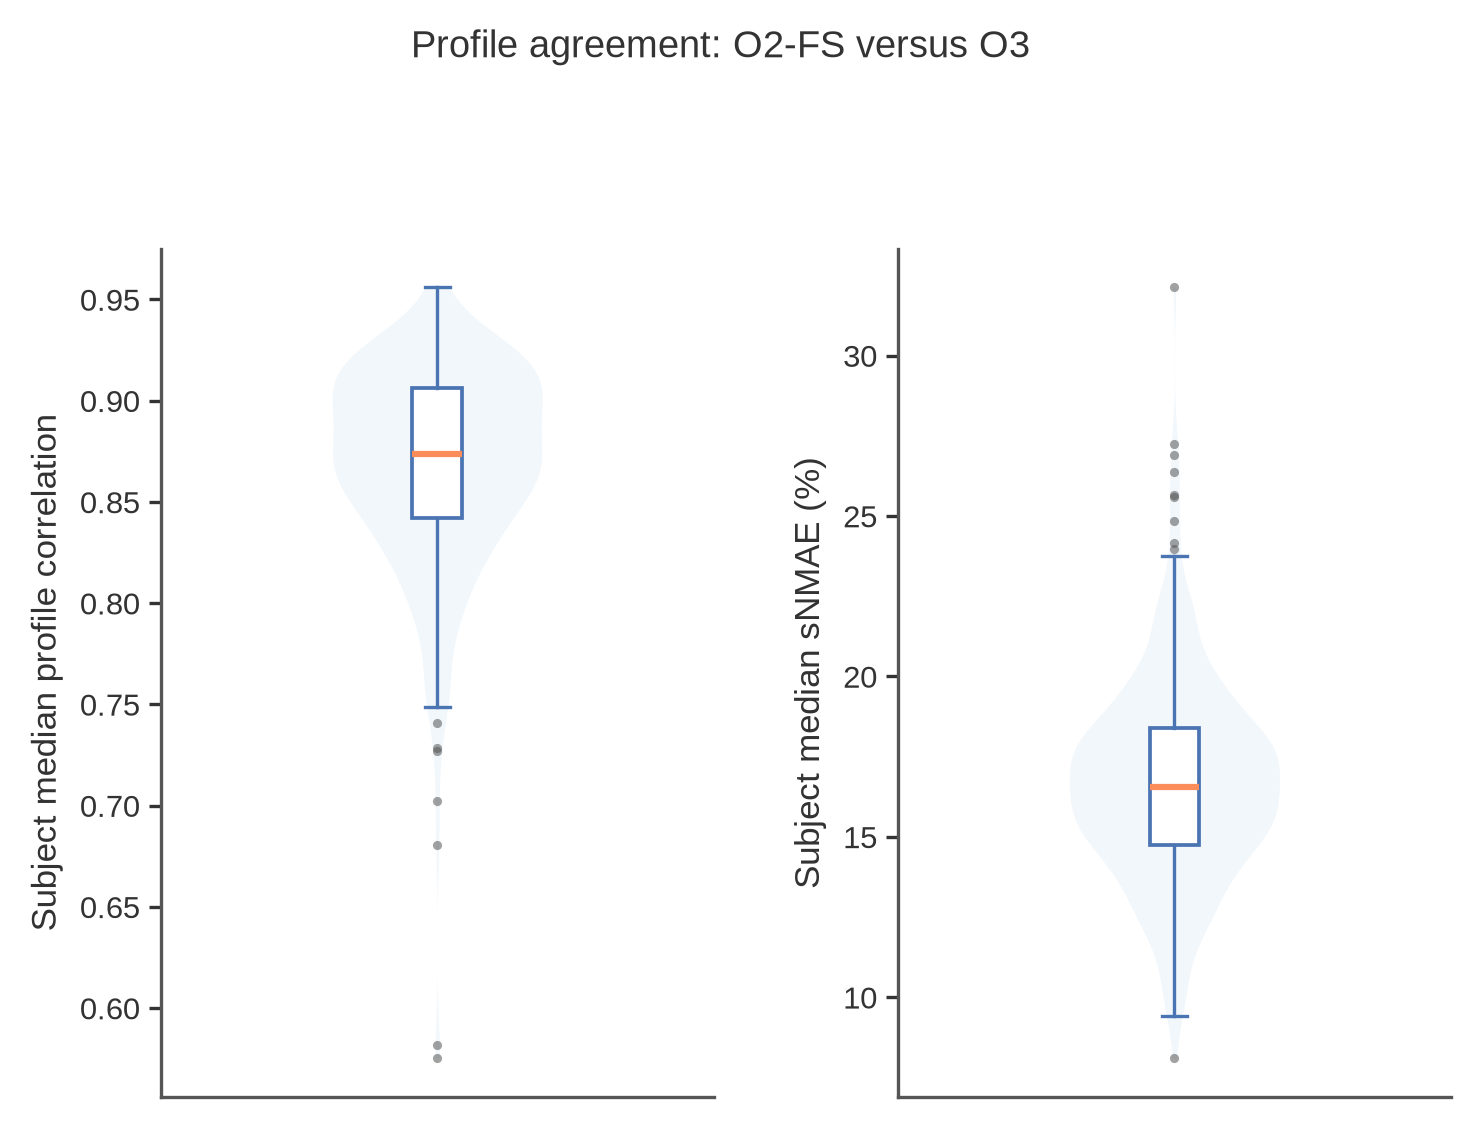

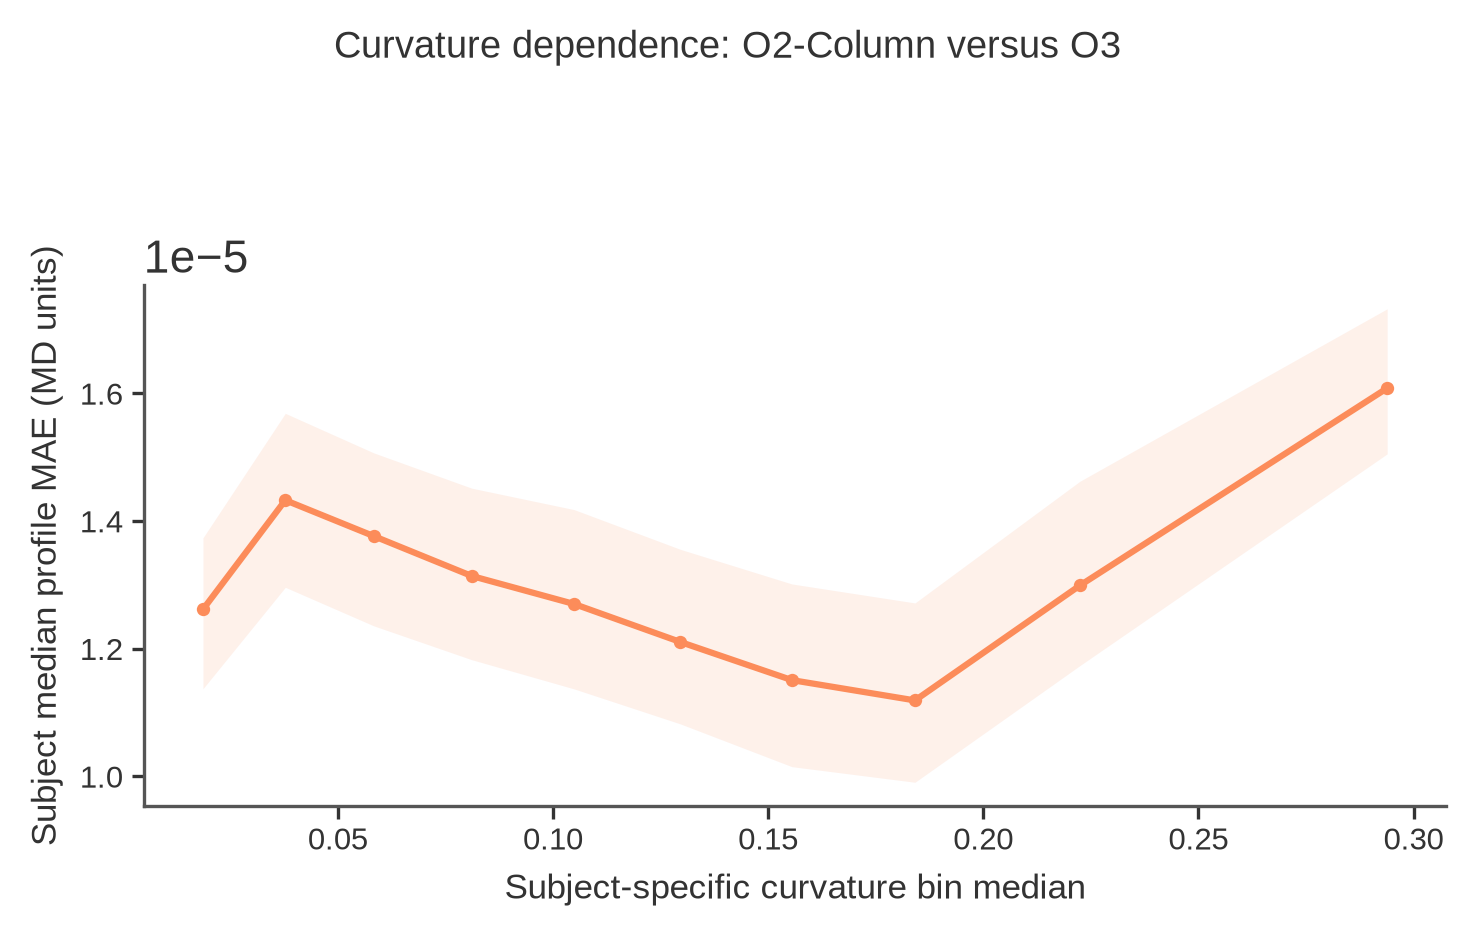

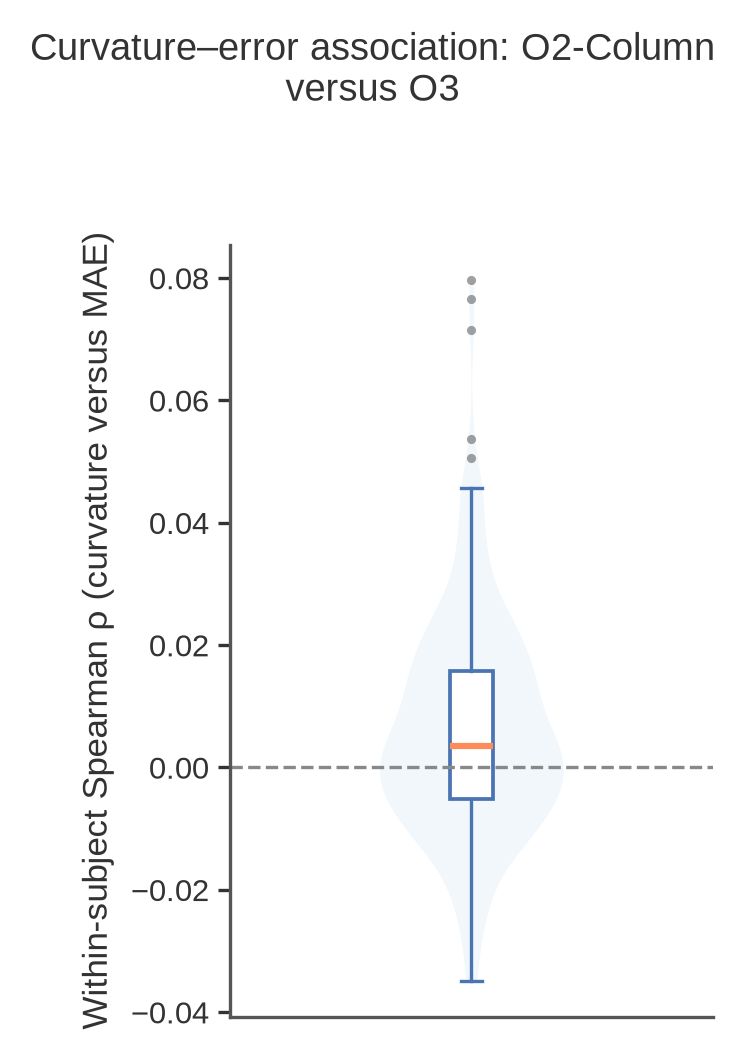

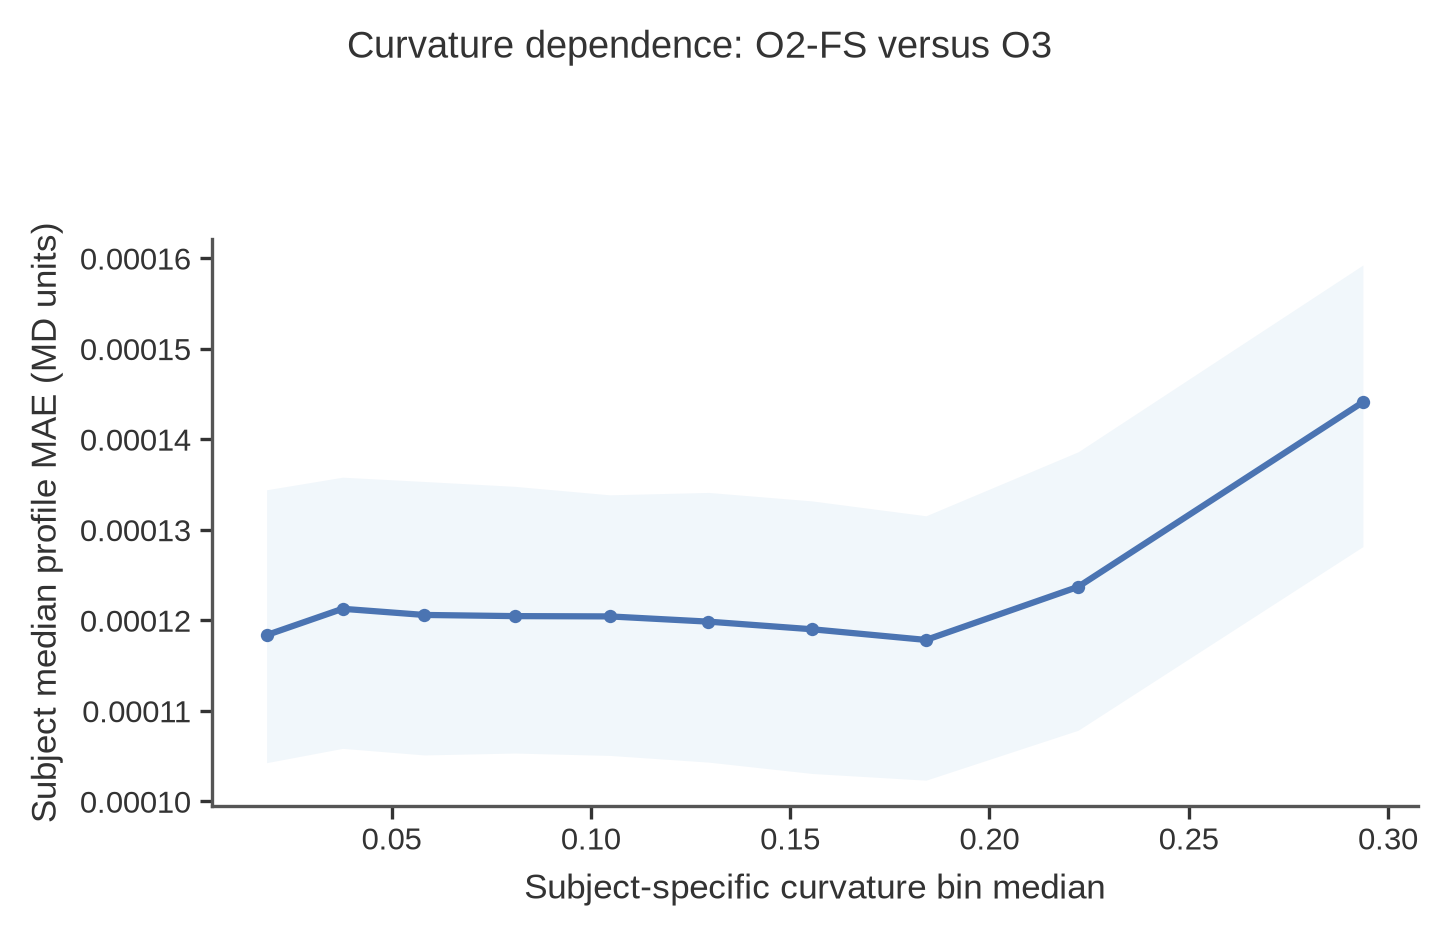

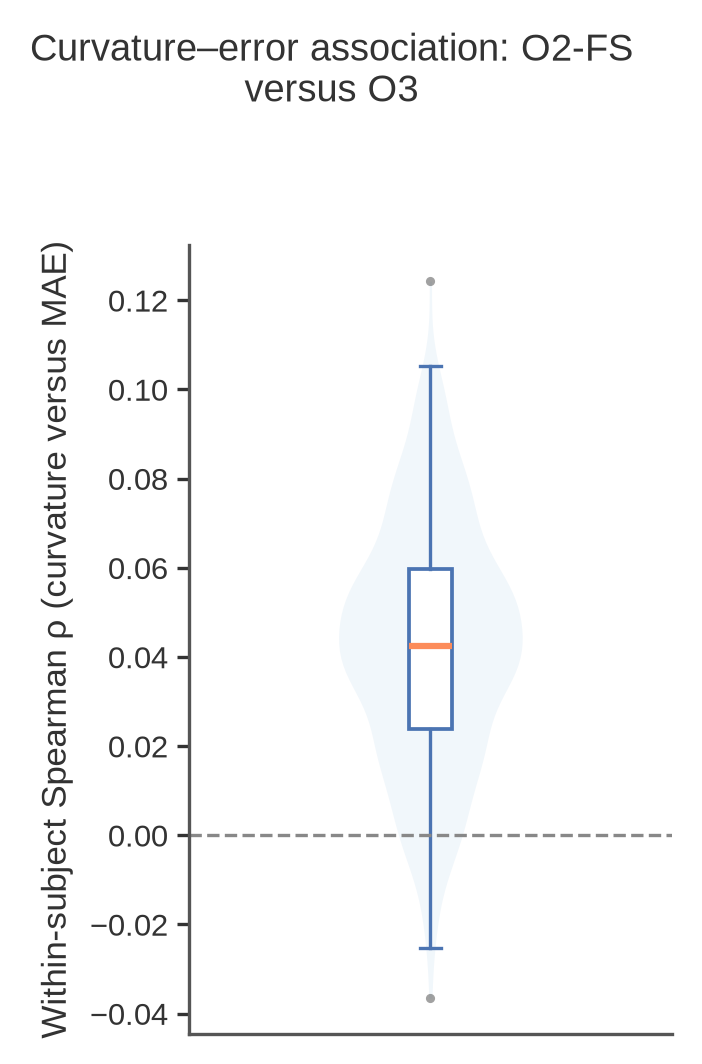

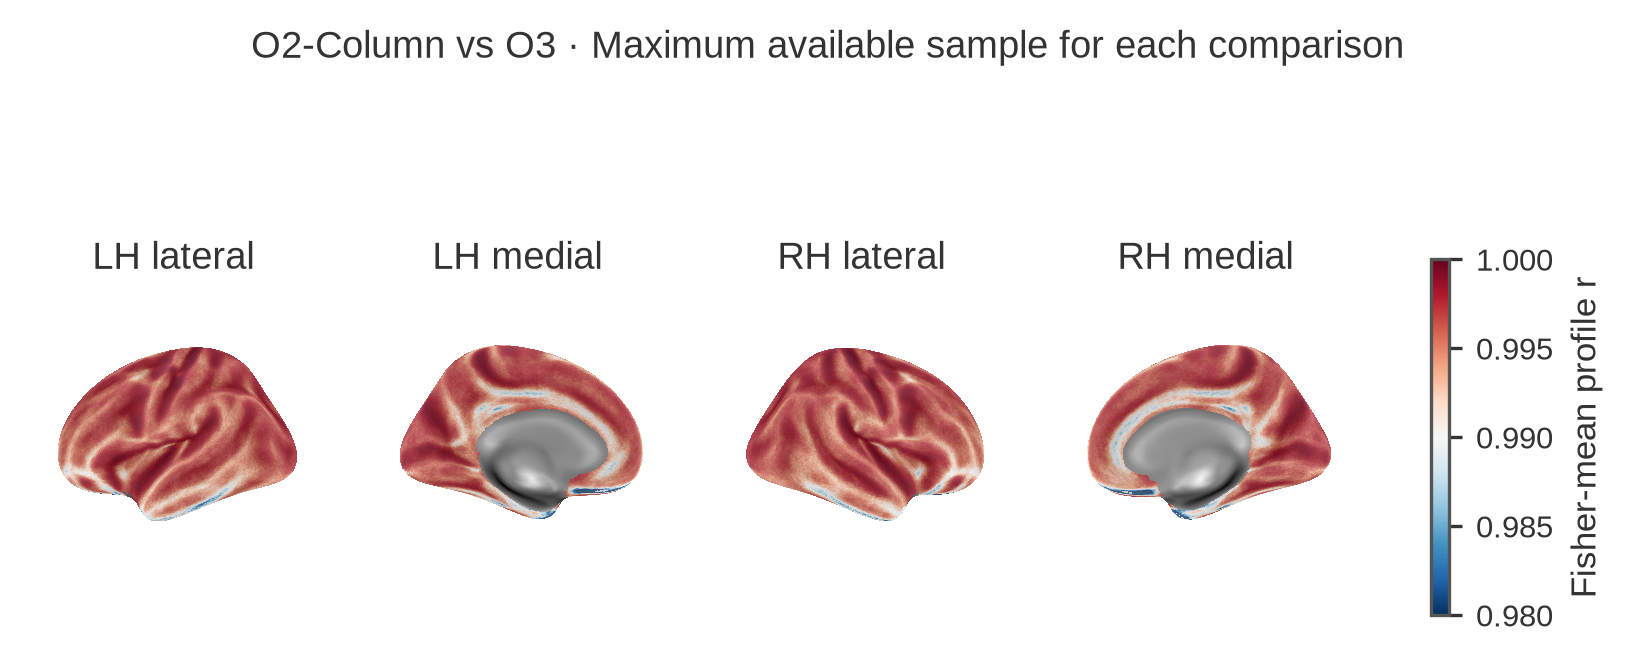

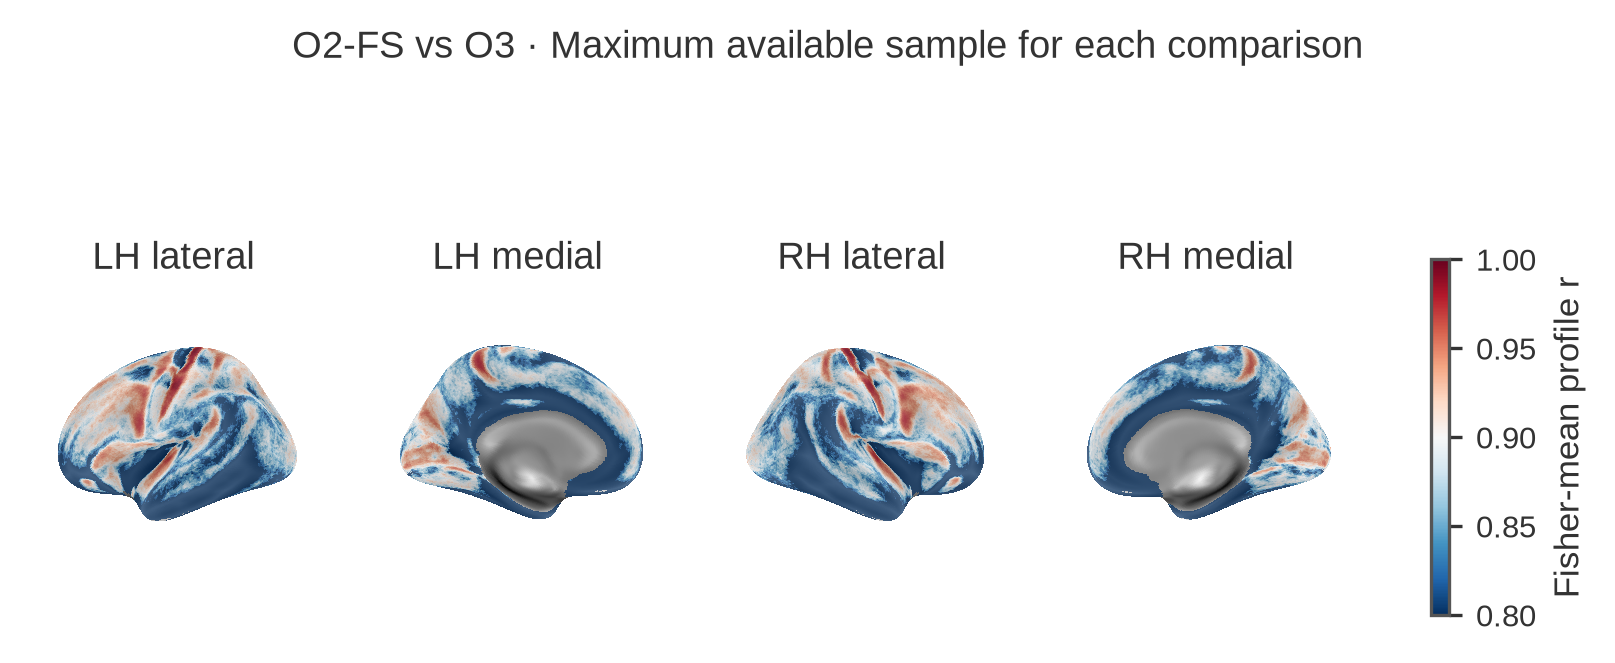

In [4]:
maximum = pd.read_csv(OUTPUT / 'max_available/subject_summary.csv')
display(maximum)
display_widths = {
    'Figure2_max_available_O2Column_vs_O3_agreement': 760,
    'Figure2_max_available_O2FS_vs_O3_agreement': 760,
    'Figure2_max_available_O2Column_vs_O3_curvature': 900,
    'Figure2_max_available_O2Column_vs_O3_curvature_association': 420,
    'Figure2_max_available_O2FS_vs_O3_curvature': 900,
    'Figure2_max_available_O2FS_vs_O3_curvature_association': 420,
    'Figure2A_max_available_O2Column_vs_O3_surface': 1300,
    'Figure2A_max_available_O2FS_vs_O3_surface': 1300,
}
for stem, width in display_widths.items():
    display(Image(filename=str(OUTPUT / 'figures' / f'{stem}.png'), width=width))



## Coverage and reproducibility

Subject-level tables and plots are read from saved artifacts. Per-vertex Parquet files are partitioned by subject and comparison, so this notebook never loads the entire cohort's vertex table into memory. Unexpected source/format/validity errors fail the subject task instead of silently changing the cohort. Final aggregation is gated on successful completion of all requested subject tasks.


In [5]:
coverage = pd.read_csv(OUTPUT / 'max_available/coverage.csv')
display(coverage.groupby('comparison').agg(n_subjects=('subject_id', 'nunique'),
       hemisphere_rows=('hemisphere', 'count'), min_pairwise_coverage=('pairwise_valid_percentage', 'min'),
       median_pairwise_coverage=('pairwise_valid_percentage', 'median')))
print('Canonical depth: 0 = pial; 1 = white; O2-FS projfrac = 1 - depth.')
print('Subject bootstrap:', report['bootstrap_repetitions'], 'samples; seed', report['bootstrap_seed'])
print('Results:', OUTPUT)
print('Per-subject inputs, metrics, source provenance and vertex Parquet:', OUTPUT / 'subjects')


,n_subjects,hemisphere_rows,min_pairwise_coverage,median_pairwise_coverage
comparison,,,,
O2Column_vs_O3,293,586,56.008297,98.725152
O2FS_vs_O3,320,640,83.297093,98.939668


Canonical depth: 0 = pial; 1 = white; O2-FS projfrac = 1 - depth.
Subject bootstrap: 10000 samples; seed 20261103
Results: /mnt/newStor/paros/paros_WORK/xintong/results/qc/template_registration_comparison/figure2_full_cohort_fsaverage
Per-subject inputs, metrics, source provenance and vertex Parquet: /mnt/newStor/paros/paros_WORK/xintong/results/qc/template_registration_comparison/figure2_full_cohort_fsaverage/subjects
